In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import matplotlib

In [3]:
#pd.options.plotting.backend = "matplotlib" 
##pd.options.plotting.backend = "plotly"
##pd.options.plotting.backend = "hvplot"

In [4]:
import seaborn as sns

In [5]:
#dat = pd.read_csv('/Users/ravirajan/Projects/TTD/bq-results-20251220-union.csv', low_memory=False).replace(' ', None)
dat = pd.read_csv('/Users/ravirajan/Projects/TTD/TTD_Raw-20260328.csv', low_memory=False).replace(' ', None)

In [6]:
dat = dat[dat.Week_Start_Date < "2026-02-16"]

In [7]:
adv_type = "Automotive"
#adv_type = "All"

In [162]:
dat.Advertiser_Category.unique()

array(['News and Politics', 'Food & Drink', 'Style & Fashion',
       'Business and Finance', 'Technology & Computing', 'All',
       'Events and Attractions', 'Travel', 'Personal Finance',
       'Automotive', 'Shopping', 'Home & Garden', 'Pets',
       'Healthy Living', 'Medical Health'], dtype=object)

In [8]:
dat.shape

(1467750, 21)

In [9]:
def get_geo(litems):
    check = ['Asia', 'US', 'Global', 'APAC']
    for c in check:
        if c in litems:
            return c
    return 'Unknown'

In [10]:
dat['geo'] = dat.Full_Path.apply(lambda x: get_geo(x.replace(" ", "").split(">")))

In [11]:
dat.groupby('geo').size()

geo
APAC         3060
Asia       311970
Global     807075
US         212025
Unknown    133620
dtype: int64

In [12]:
dat.head()

,Active_ID_Count,Active_ID_Count_Percentile,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,...,Paid_Pct,Paid_Pct_Percentile,Received_ID_Count,Selected_Pct,Selected_Pct_Percentile,Third_Party_Data_Provider_Element_Id,Third_Party_Data_Provider_Id,Third_Party_Data_Sub_Provider_Id,Week_Start_Date,geo
0,NaN,NaN,News and Politics,2.7,54.8,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,NaN,NaN,NaN,NaN,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global
1,NaN,NaN,Food & Drink,3.3,67.4,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,NaN,NaN,NaN,NaN,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global
2,NaN,NaN,Style & Fashion,3.8,85.3,NaN,NaN,NaN,NaN,Data Alliance > CPG > Interest > Global > Food...,...,NaN,NaN,NaN,NaN,NaN,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global
3,341886000.0,99.4,Food & Drink,3.8,75.5,98.4,68.0,0.11,24168.0,Data Alliance > Retail > Interest > Global > M...,...,12.5,91.4,730559200.0,0.0245,96.9,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global
4,NaN,NaN,Business and Finance,3.9,77.4,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,NaN,NaN,NaN,NaN,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global


In [13]:
dat['Clean_Path'] = dat.Full_Path.apply(lambda x: x.lower().replace(" ", ""))

array([[<Axes: title={'center': 'Received_ID_Count'}>]], dtype=object)

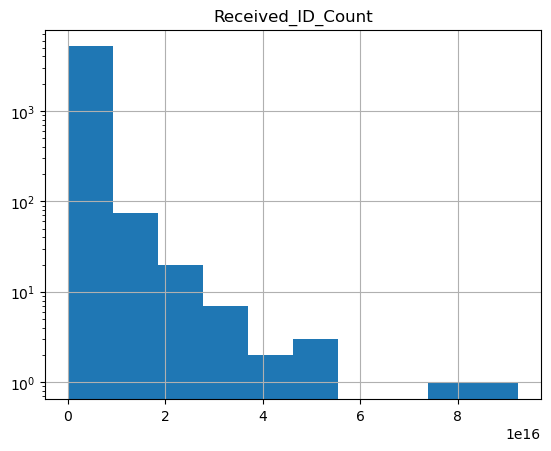

In [14]:
dat.groupby('Clean_Path')[['Received_ID_Count']].var().hist(log=True)

In [15]:
dat['segment_last'] = dat.Clean_Path.apply(lambda x: x.split(">")[-1].replace("age", ""))
dat['segment_1'] = dat.Clean_Path.apply(lambda x: x.split(">")[0])
##dat['segment_2'] = dat.Clean_Path.apply(lambda x: x.split(">")[1] if len(x.split(">")) > 1 else "N/A")
dat['segment_2'] = dat.Clean_Path.apply(lambda x: x.replace("otp>", "").split(">")[1] if len(x.split(">")) > 1 else "N/A")
dat['week_start'] = dat.Week_Start_Date.apply(lambda x: x.split(" ")[0])

In [16]:
dat.groupby('Third_Party_Data_Provider_Id')['segment_last'].unique()

Third_Party_Data_Provider_Id
dav2shreths    [aprilia, model3, frozen, books, xc40, comics,...
sharethis      [females18-54, females25-34, waterfilters&puri...
Name: segment_last, dtype: object

In [17]:
#seg_last_vb = list(dat[dat.Third_Party_Data_Provider_Id == 'sharethis']['segment_last'].unique())
#seg_last_da = list(dat[dat.Third_Party_Data_Provider_Id == 'dav2shreths']['segment_last'].unique())

In [18]:
seg_last_vb = pd.DataFrame(dat[dat.Third_Party_Data_Provider_Id == 'sharethis']['segment_last'].value_counts())
seg_last_da = pd.DataFrame(dat[dat.Third_Party_Data_Provider_Id == 'dav2shreths']['segment_last'].value_counts())

In [19]:
seg_last_vb.describe()

,count
count,1724.000000
mean,533.378770
std,257.777392
min,30.000000
25%,255.000000
50%,510.000000
75%,765.000000
max,2295.000000


In [20]:
seg_last_da.describe()

,count
count,1776.000000
mean,308.673986
std,248.051338
min,30.000000
25%,255.000000
50%,255.000000
75%,255.000000
max,8670.000000


In [21]:
len(set(dat['segment_last']))

3214

In [22]:
def find_common_substrings(list1, list2, fuzzy_only=True):
    """
    Finds all strings from list1 that are substrings of any string in list2.
    """
    common_subs = set()
    matches = []
    exact_matches = set()
    for s1 in list1:
        for s2 in list2:
            if s1 == s2:
                exact_matches.add(s1)
                if fuzzy_only:
                    continue
            if len(s1) > 2 and s1.lower() in s2.lower():
                common_subs.add(s1.lower())
                matches.append([s1, s2])
            elif len(s2) > 2 and s2.lower() in s1.lower():
                common_subs.add(s2.lower())
                matches.append([s1, s2])
    return list(common_subs), matches, exact_matches

In [23]:
seg_common, matches, exact_matches = find_common_substrings(seg_last_vb[seg_last_vb["count"] > 1].index, 
                                             seg_last_da[seg_last_da["count"] > 1].index)
len(seg_common)

509

In [24]:
#matches

In [25]:
#exact_matches

In [26]:
#for k in exact_matches:
#    print (k, seg_last_vb.loc[k].values[0], seg_last_da.loc[k].values[0])

In [27]:
dat.tail()

,Active_ID_Count,Active_ID_Count_Percentile,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,...,Third_Party_Data_Provider_Element_Id,Third_Party_Data_Provider_Id,Third_Party_Data_Sub_Provider_Id,Week_Start_Date,geo,Clean_Path,segment_last,segment_1,segment_2,week_start
1811927,NaN,NaN,Style & Fashion,1.8,38.1,NaN,NaN,NaN,NaN,Asia > Computers & Electronics > Enterprise Te...,...,aa6c9420,sharethis,None,2026-02-09 00:00:00+00,Asia,asia>computers&electronics>enterprisetechnolog...,datamanment,asia,computers&electronics,2026-02-09
1811928,NaN,NaN,Food & Drink,1.5,31.4,NaN,NaN,NaN,NaN,Asia > Computers & Electronics > Enterprise Te...,...,52936406,sharethis,None,2026-02-09 00:00:00+00,Asia,asia>computers&electronics>enterprisetechnolog...,enterpriseresourceplanning(erp),asia,computers&electronics,2026-02-09
1811929,NaN,NaN,Medical Health,2.8,52.7,NaN,NaN,NaN,NaN,Asia > Computers & Electronics > Networking,...,072e24ed,sharethis,None,2026-02-09 00:00:00+00,Asia,asia>computers&electronics>networking,networking,asia,computers&electronics,2026-02-09
1811930,NaN,NaN,Technology & Computing,1.7,38.0,NaN,NaN,NaN,NaN,Asia > Computers & Electronics > Networking,...,072e24ed,sharethis,None,2026-02-09 00:00:00+00,Asia,asia>computers&electronics>networking,networking,asia,computers&electronics,2026-02-09
1811931,NaN,NaN,Automotive,2.0,42.9,NaN,NaN,NaN,NaN,Asia > Computers & Electronics > Networking > ...,...,3da8742d,sharethis,None,2026-02-09 00:00:00+00,Asia,asia>computers&electronics>networking>dataform...,dataformats&protocols,asia,computers&electronics,2026-02-09


In [28]:
len(dat['segment_last'].unique()), len(dat['segment_1'].unique()), len(dat['segment_2'].unique())

(3214, 11, 90)

In [29]:
dat.groupby(['Third_Party_Data_Provider_Id','segment_last']).size()

Third_Party_Data_Provider_Id  segment_last                
dav2shreths                   1-3months                       255
                              1-star                          255
                              10+vehicles                     255
                              1500                            255
                              18-20                           255
                                                             ... 
sharethis                     yoga&pilates                    765
                              yogurt                          255
                              youthorganizations&resources    285
                              zeroproof                       255
                              zoos-aquariums-preserves        765
Length: 3500, dtype: int64

In [30]:
dat.groupby(['Third_Party_Data_Provider_Id','segment_last']).size().groupby('Third_Party_Data_Provider_Id').size()

Third_Party_Data_Provider_Id
dav2shreths    1776
sharethis      1724
dtype: int64

In [31]:
dat.groupby(['geo','segment_last']).size().groupby('geo').size()

geo
APAC         12
Asia       1173
Global     2579
US          825
Unknown     462
dtype: int64

In [32]:
dat['segment_1'].unique()

array(['dataalliance', 'asia', 'political', 'otp', 'intent', 'us', 'b2b',
       'interestfromsocialactivity', 'global', 'winterholiday',
       'unavailable'], dtype=object)

In [33]:
#seg1 = 'otp'
#dat[dat.segment_1 == seg1]['Full_Path'].values[-10:]

#otp -> 3rd & last
#b2b -> 2nd & last
#datalliance -> 2nd & last
# interestfromsocialactivity -> last
# global -> 2nd & last
# us -> last (or 3rd?)
# politcal -> last
# intent -> 2nd & last?
# winterholiday -> last or 2nd
# asian -> 2nd & last?

In [34]:
dat['segment_2'].unique()

array(['automotive', 'cpg', 'retail', 'books&literature',
       'technology&computing', 'style&fashion', 'travel',
       'business&finance', 'career&jobs', 'health&wellness', 'education',
       'arts&entertainment', 'food&beverages', 'realestate',
       'games&gaming', 'pets&animals', 'sports', 'home&garden',
       'lifestyle&living', 'hobbies&interests', 'demographic',
       'news&politics', 'shopping', 'validateddemographic',
       'people&society', 'intent', 'seasonal', 'autos&vehicles',
       'computers&electronics', 'law&government', 'jobs&education',
       'news', 'business&industrial', 'reference', 'food&drink',
       'beauty&fitness', 'finance', 'politician', 'onlinecommunities',
       'thechangingconsumer', 'games', 'internet&telecom', 'lifeevent',
       'hobbies&leisure', 'dataforgood', 'science', 'industry',
       'autobuyers', 'sentiment', 'functionalarea', 'occupation',
       'health', 'seniority', 'politcalaffiliation', 'politicalissue',
       'global', 'pr

In [35]:
dat.groupby('geo').size()

geo
APAC         3060
Asia       311970
Global     807075
US         212025
Unknown    133620
dtype: int64

# EDA

In [36]:
dat1 = dat[dat.Received_ID_Count.isna() == False]
#dat1 = dat1[dat1.Advertiser_Category == 'All']  
dat1 = dat1[dat1.Advertiser_Category == adv_type]  
dat1.shape

(13924, 27)

In [37]:
dat1['Received_ID_Count'] = dat1['Received_ID_Count'].astype(int)
dat1['Active_ID_Count'] = dat1['Active_ID_Count'].astype(int)
dat1['Effective_Impression_Count'] = dat1['Effective_Impression_Count'].astype(int)

In [38]:
dat['Data_Cost'] = dat['Data_Cost'].astype(float)
dat1['Match_Pct'] = dat1['Match_Pct'].astype(float)
dat1['Match_Pct_Percentile'] = dat1['Match_Pct_Percentile'].astype(float)

In [39]:
dat1_sample = dat1.sample(1000)
dat1_sample.head()

,Active_ID_Count,Active_ID_Count_Percentile,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,...,Third_Party_Data_Provider_Element_Id,Third_Party_Data_Provider_Id,Third_Party_Data_Sub_Provider_Id,Week_Start_Date,geo,Clean_Path,segment_last,segment_1,segment_2,week_start
831134,44878400,98.1,Automotive,5.5,95.0,99.2,73.0,0.0,109,US > autos & vehicles > vehicle brands > Tesla...,...,NaN,sharethis,None,2025-11-17 00:00:00+00,US,us>autos&vehicles>vehiclebrands>tesla>teslamodels,teslamodels,us,autos&vehicles,2025-11-17
1223759,16410400,98.1,Automotive,5.1,88.8,98.3,64.0,0.0,3,Intent > Auto Buyers > Type > Crossover,...,3ecd2542,sharethis,None,2026-02-09 00:00:00+00,Unknown,intent>autobuyers>type>crossover,crossover,intent,autobuyers,2026-02-09
1712711,8179200,97.7,Automotive,5.9,91.0,98.5,73.0,0.0,500,Data Alliance > Business & Finance > Interest ...,...,NaN,dav2shreths,None,2026-01-05 00:00:00+00,Global,dataalliance>business&finance>interest>global>...,businessmanment,dataalliance,business&finance,2026-01-05
783384,32654600,97.9,Automotive,5.0,92.6,98.8,66.0,0.0,17,Data Alliance > Health & Wellness > Interest >...,...,NaN,dav2shreths,None,2025-11-03 00:00:00+00,Global,dataalliance>health&wellness>interest>global>p...,nailcare,dataalliance,health&wellness,2025-11-03
769930,299600,91.3,Automotive,1.4,37.6,91.0,31.0,0.0,121,Asia > Food & Drink > Food & Grocery Retailers...,...,NaN,sharethis,None,2025-10-27 00:00:00+00,Asia,asia>food&drink>food&groceryretailers>farmersm...,farmersmarkets,asia,food&drink,2025-10-27


In [40]:
dat1_sample['revenue_per_user'] = dat1_sample['Data_Cost'] / dat1_sample['Received_ID_Count']
dat1_sample['revenue_per_active_user'] = dat1_sample['Data_Cost'] / dat1_sample['Active_ID_Count']

In [41]:
dat1_sample['ecpm'] = dat1_sample['Data_Cost'] / dat1_sample['Effective_Impression_Count']

<Axes: title={'center': 'number of segments'}, xlabel='week_start'>

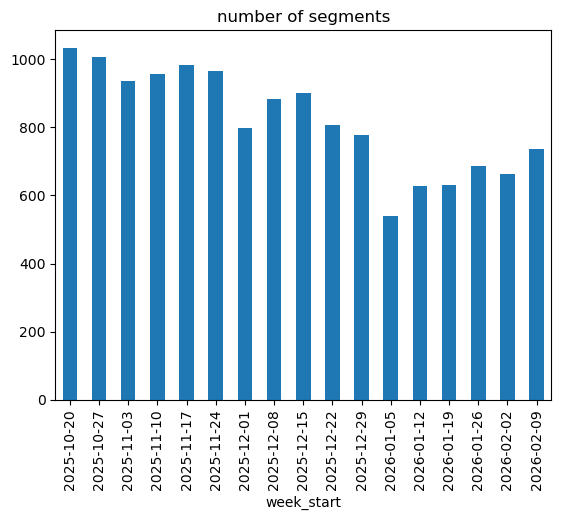

In [42]:
dat1.groupby('week_start').size().plot(kind='bar', title='number of segments')

In [43]:
def get_split_means(dat1_sample, value = 'Avg_Relevance'):
    return dat1_sample.groupby(['week_start', 'Third_Party_Data_Provider_Id'])[[value]].mean().pivot_table(
    index='week_start', columns='Third_Party_Data_Provider_Id', values=value)

def get_split_plots(dat1_sample, x, y, kind='scatter', logx=False, logy=False):
    ax=None
    ax=dat1_sample[dat1_sample.Third_Party_Data_Provider_Id == 'sharethis'].plot(ax=ax, kind=kind, x=x, y=y, logx=logx, logy=logy, label='branded taxonomy', color='green')
    ax=dat1_sample[dat1_sample.Third_Party_Data_Provider_Id != 'sharethis'].plot(ax=ax, kind=kind, x=x, y=y, logx=logx, logy=logy, label='data alliance', color='orange')
    return ax

from matplotlib.pyplot import cm
def get_split_plots2(dat1_sample, x, y, kind='scatter', by='geo', logx=False, logy=False, alpha=1):
    ax=None
    vals = set(dat1_sample[by].values)
    color = cm.rainbow(np.linspace(0, 1, len(vals)))
    for i, val in enumerate(vals):
        ax=dat1_sample[dat1_sample[by] == val].plot(ax=ax, kind=kind, x=x, y=y, logx=logx, logy=logy, label=val, color=color[i], alpha=alpha)
    return ax

In [44]:
get_split_means(dat1_sample, value = 'Avg_Relevance')

Third_Party_Data_Provider_Id,dav2shreths,sharethis
week_start,,
2025-10-20,4.973333,4.240909
2025-10-27,5.036000,4.269388
2025-11-03,5.040000,4.004348
2025-11-10,5.019048,3.991489
2025-11-17,5.091304,3.906000
2025-11-24,6.288000,4.325532
2025-12-01,6.041176,4.956410
2025-12-08,6.129412,4.183333
2025-12-15,5.806250,4.137500


In [45]:
get_split_means(dat1_sample, value = 'Data_Cost')

Third_Party_Data_Provider_Id,dav2shreths,sharethis
week_start,,
2025-10-20,33.519000,85.432273
2025-10-27,7.708800,3.006327
2025-11-03,26.677600,3.084130
2025-11-10,1.111429,3.400000
2025-11-17,2.150870,0.812400
2025-11-24,141.766400,2.497021
2025-12-01,11.681765,3.338974
2025-12-08,26.566471,1.512500
2025-12-15,6.826875,0.845625


<Axes: title={'center': 'avg(relevance) over time'}, xlabel='week_start', ylabel='relevance'>

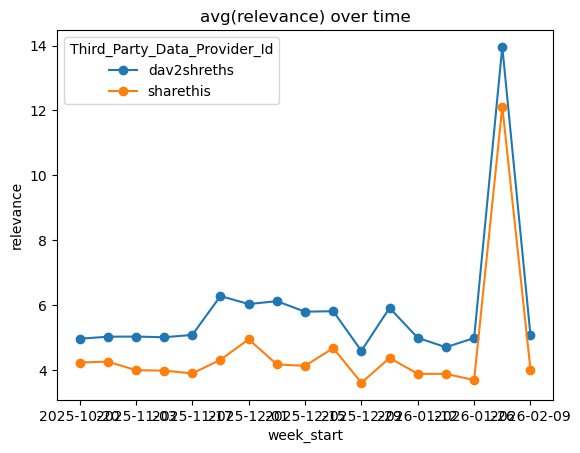

In [46]:
get_split_means(dat1_sample, value = 'Avg_Relevance').plot(marker='o', title='avg(relevance) over time', ylabel='relevance')

<Axes: title={'center': 'avg(revenue) over time'}, xlabel='week_start', ylabel='revenue'>

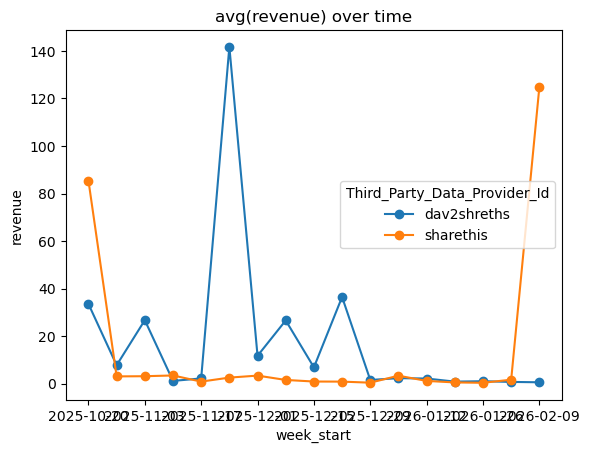

In [47]:
get_split_means(dat1_sample, value = 'Data_Cost').plot(marker='o', title='avg(revenue) over time', ylabel='revenue')

In [48]:
dat1[['Data_Cost', 'Avg_Relevance', 'Avg_Relevance_Percentile']].corr()

,Data_Cost,Avg_Relevance,Avg_Relevance_Percentile
Data_Cost,1.000000,0.026653,0.025578
Avg_Relevance,0.026653,1.000000,0.668325
Avg_Relevance_Percentile,0.025578,0.668325,1.000000


<Axes: xlabel='week_start'>

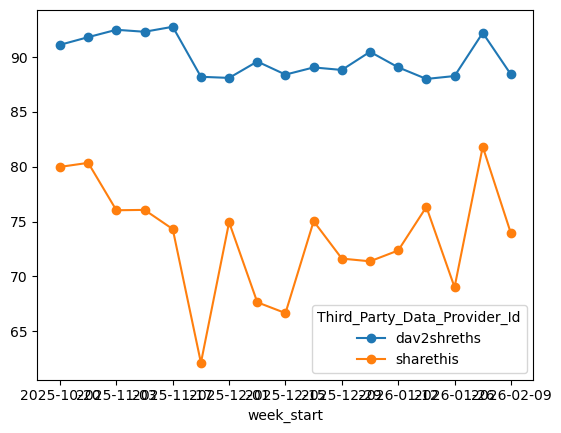

In [49]:
get_split_means(dat1_sample, value = 'Avg_Relevance_Percentile').plot(marker='o')

<Axes: xlabel='Received_ID_Count', ylabel='Active_ID_Count'>

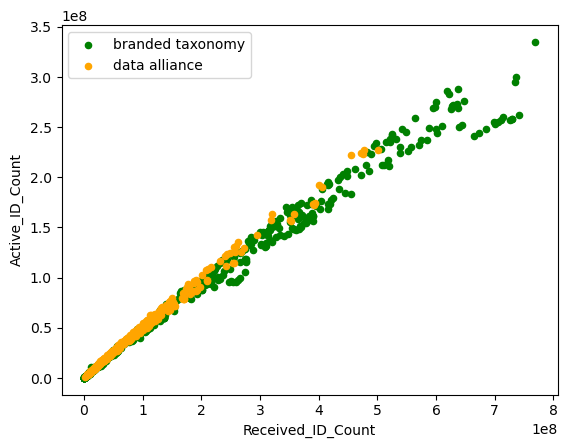

In [50]:
get_split_plots(dat1_sample, x='Received_ID_Count', y='Active_ID_Count')
#get_split_plots2(dat1_sample, x='Received_ID_Count', y='Active_ID_Count', by='geo')

<Axes: >

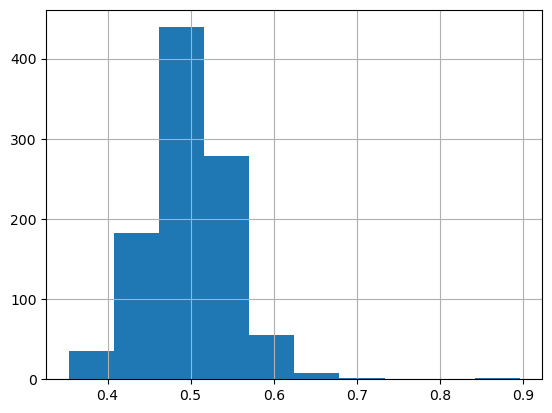

In [51]:
(dat1_sample['Active_ID_Count'] / dat1_sample['Received_ID_Count']).hist()

In [52]:
(dat1_sample['Active_ID_Count'] / dat1_sample['Received_ID_Count']).mean()

0.49833973953192756

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='Effective_Impression_Count'>

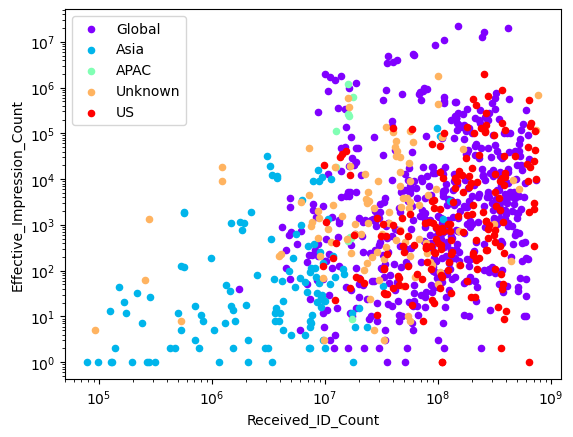

In [53]:
#get_split_plots(dat1_sample, x='Received_ID_Count', y='Effective_Impression_Count', logy=True, logx=True)
get_split_plots2(dat1_sample, x='Received_ID_Count', y='Effective_Impression_Count', by='geo', logy=True, logx=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='Effective_Impression_Count'>

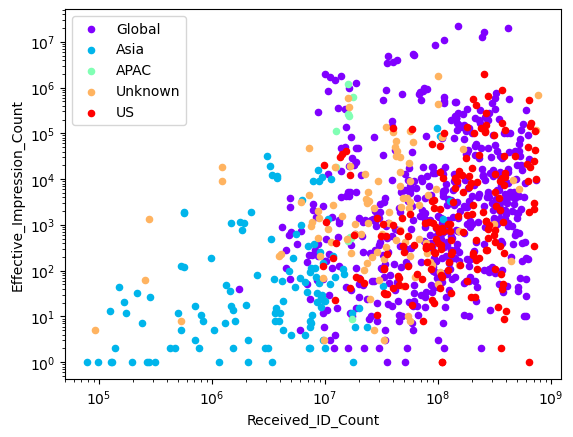

In [54]:
#get_split_plots(dat1_sample, x='Received_ID_Count', y='Effective_Impression_Count', logy=True, logx=True)
get_split_plots2(dat1_sample, x='Received_ID_Count', y='Effective_Impression_Count', by='geo', logy=True, logx=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Active_ID_Count', ylabel='Effective_Impression_Count'>

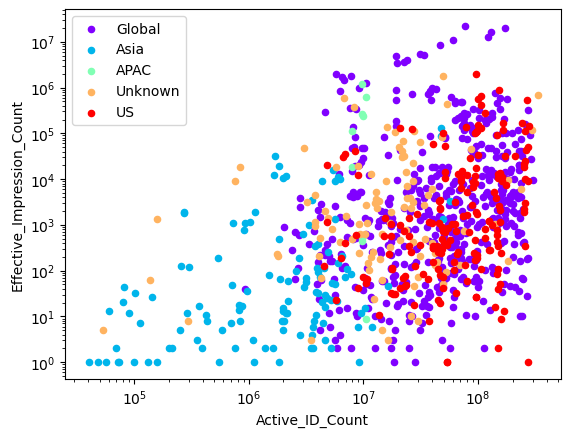

In [55]:
#get_split_plots(dat1_sample, x='Active_ID_Count', y='Effective_Impression_Count', logy=True, logx=True)
get_split_plots2(dat1_sample, x='Active_ID_Count', y='Effective_Impression_Count', by='geo', logy=True, logx=True)

<Axes: xlabel='Avg_Relevance', ylabel='Effective_Impression_Count'>

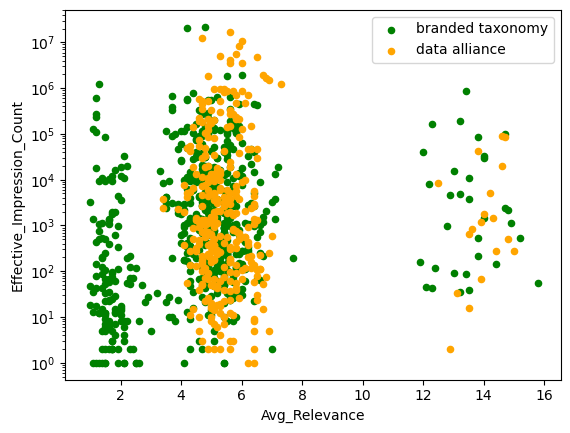

In [56]:
get_split_plots(dat1_sample, x='Avg_Relevance', y='Effective_Impression_Count', logy=True, logx=False)

<Axes: xlabel='Effective_Impression_Count', ylabel='Data_Cost'>

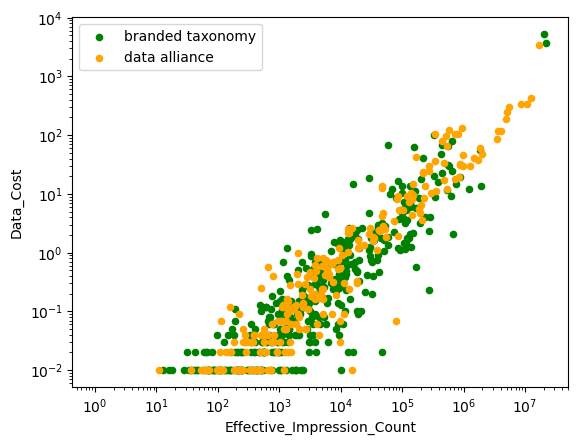

In [57]:
get_split_plots(dat1_sample, y='Data_Cost', x='Effective_Impression_Count', logy=True, logx=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='Avg_Relevance'>

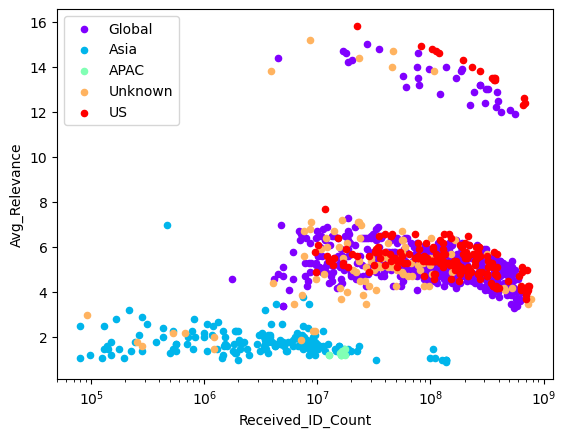

In [58]:
get_split_plots2(dat1_sample, y='Avg_Relevance', x='Received_ID_Count', by='geo', logy=False, logx=True)

<Axes: xlabel='Received_ID_Count', ylabel='Match_Pct'>

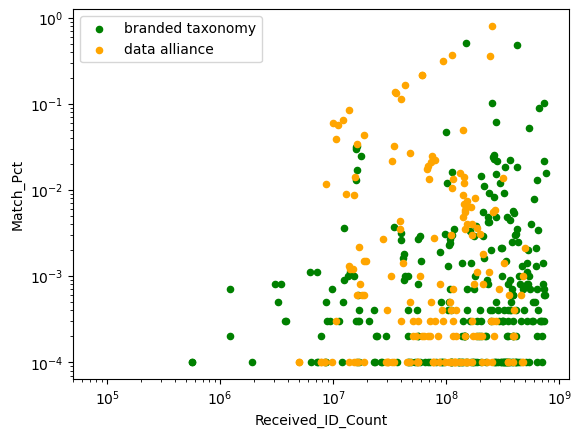

In [59]:
get_split_plots(dat1_sample, y='Match_Pct', x='Received_ID_Count', logy=True, logx=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='Data_Cost'>

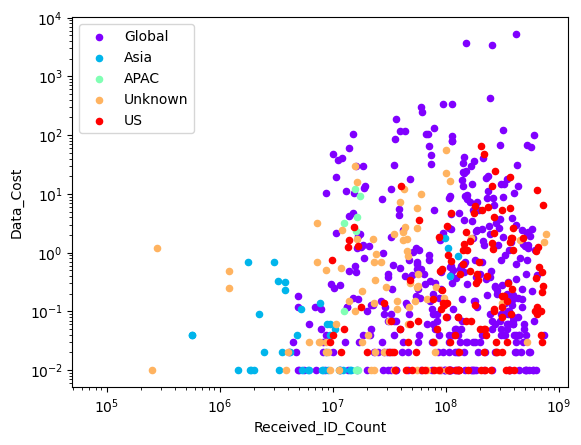

In [60]:
get_split_plots2(dat1_sample, x='Received_ID_Count', y='Data_Cost', kind='scatter', by='geo', logx=True, logy=True)

<Axes: xlabel='Avg_Relevance', ylabel='revenue_per_user'>

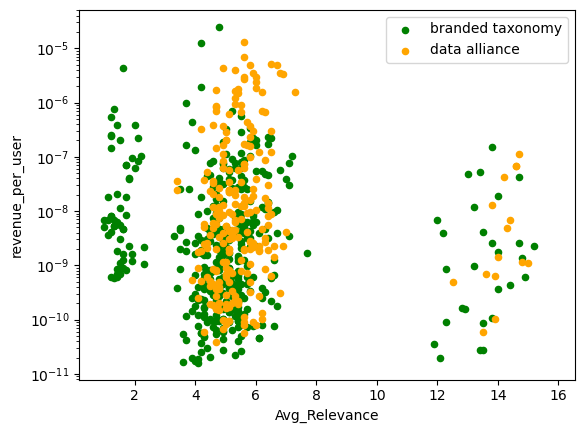

In [61]:
get_split_plots(dat1_sample, y='revenue_per_user', x='Avg_Relevance', logy=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Avg_Relevance', ylabel='revenue_per_user'>

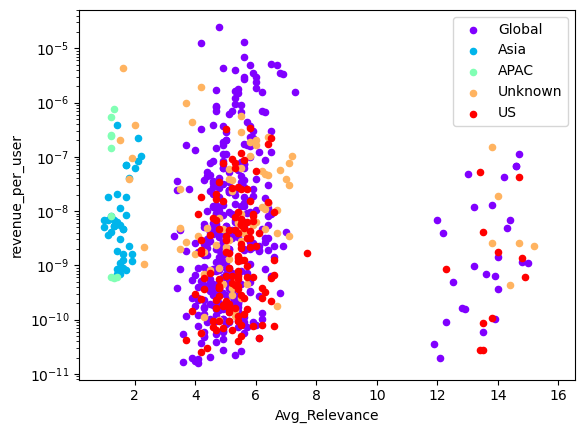

In [62]:
get_split_plots2(dat1_sample, x='Avg_Relevance', y='revenue_per_user', kind='scatter', by='geo', logx=False, logy=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='revenue_per_user'>

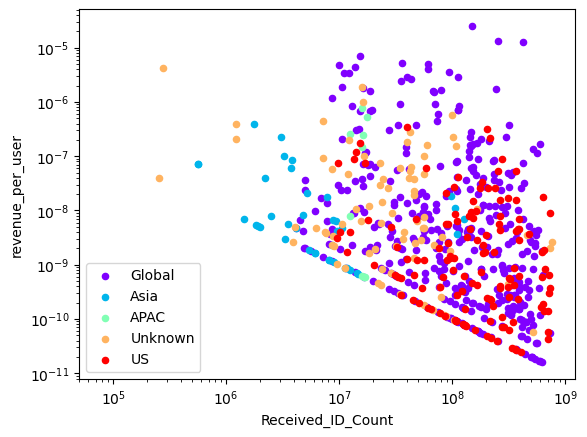

In [63]:
get_split_plots2(dat1_sample, x='Received_ID_Count', y='revenue_per_user', kind='scatter', by='geo', logx=True, logy=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Avg_Relevance', ylabel='ecpm'>

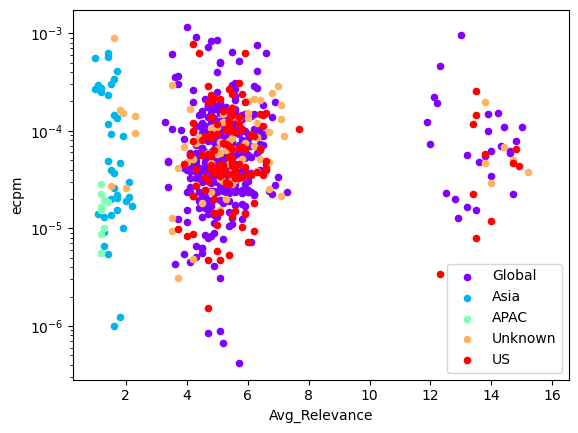

In [64]:
get_split_plots2(dat1_sample, x='Avg_Relevance', y='ecpm', kind='scatter', by='geo', logx=False, logy=True)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='ecpm', ylabel='Data_Cost'>

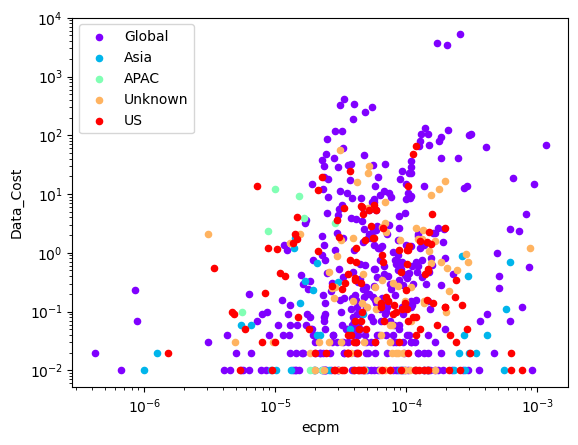

In [65]:
get_split_plots2(dat1_sample, y='Data_Cost', x='ecpm', kind='scatter', by='geo', logx=True, logy=True)

<Axes: xlabel='Avg_Relevance', ylabel='Match_Pct'>

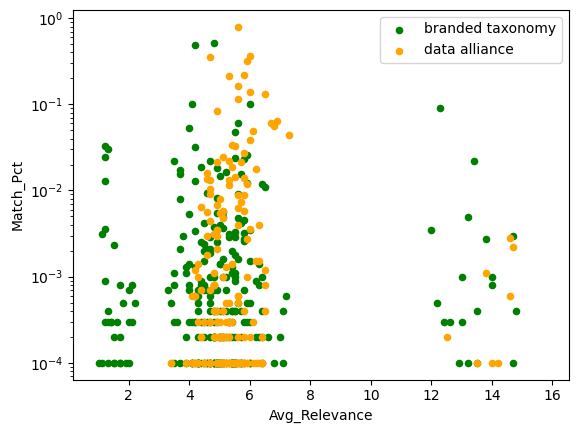

In [66]:
get_split_plots(dat1_sample, y='Match_Pct', x='Avg_Relevance', logy=True, logx=False)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Avg_Relevance', ylabel='Data_Cost'>

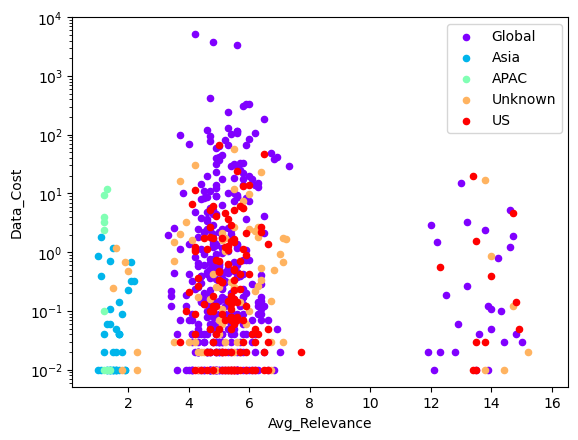

In [67]:
#get_split_plots(dat1_sample, y='Data_Cost', x='Avg_Relevance', logy=True, logx=False)
get_split_plots2(dat1_sample, y='Data_Cost', x='Avg_Relevance', by='geo', logy=True, logx=False)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Avg_Relevance_Percentile', ylabel='Data_Cost'>

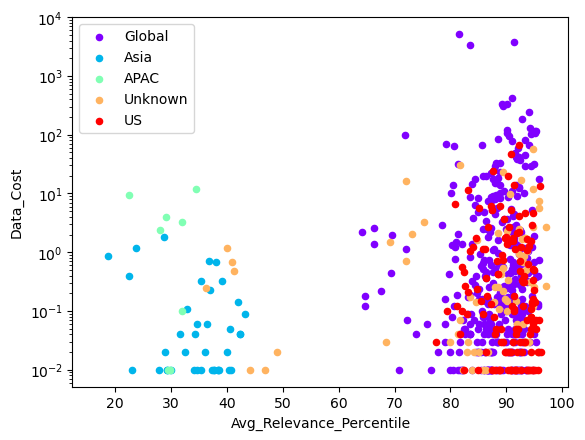

In [68]:
#get_split_plots(dat1_sample, y='Data_Cost', x='Avg_Relevance_Percentile', logy=True, logx=False)
get_split_plots2(dat1_sample, y='Data_Cost', by='geo', x='Avg_Relevance_Percentile', logy=True, logx=False)

In [69]:
dat1[['Received_ID_Count', 'Active_ID_Count', 'Effective_Impression_Count', 'Avg_Relevance', 'Match_Pct', 'Avg_Relevance_Percentile']].astype(float).describe(
    percentiles = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]
).round(2)

,Received_ID_Count,Active_ID_Count,Effective_Impression_Count,Avg_Relevance,Match_Pct,Avg_Relevance_Percentile
count,1.392400e+04,1.392400e+04,13924.00,13924.00,13924.00,13924.00
mean,1.383818e+08,6.323544e+07,189581.64,4.90,0.01,78.74
std,1.697538e+08,7.253705e+07,1248928.94,2.34,0.05,21.23
min,0.000000e+00,3.600000e+03,0.00,0.80,0.00,12.10
5%,8.427550e+05,4.442300e+05,0.00,1.40,0.00,32.40
10%,3.987250e+06,2.129310e+06,3.00,1.70,0.00,37.50
25%,1.591448e+07,8.453950e+06,46.00,4.20,0.00,80.00
50%,6.269890e+07,3.221495e+07,697.00,5.00,0.00,88.30
75%,1.958799e+08,9.365450e+07,10111.50,5.60,0.00,91.90
90%,3.981887e+08,1.767175e+08,137388.90,6.40,0.00,93.90


array([[<Axes: title={'center': 'Received_ID_Count'}>,
        <Axes: title={'center': 'Effective_Impression_Count'}>]],
      dtype=object)

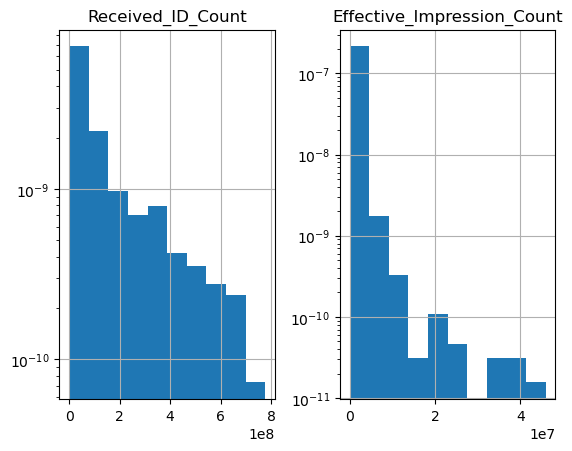

In [70]:
dat1[['Received_ID_Count', 'Effective_Impression_Count']].astype(float).hist(density=True, log=True)

In [71]:
#dat1.hist(column=['Received_ID_Count', 'Effective_Impression_Count'], density=True, by='Third_Party_Data_Provider_Id', log=True)

In [72]:
dat1[['Received_ID_Count', 'Effective_Impression_Count']].astype(float).describe(
    percentiles = [0.1, 0.5, 0.9]
).round(2)

,Received_ID_Count,Effective_Impression_Count
count,1.392400e+04,13924.00
mean,1.383818e+08,189581.64
std,1.697538e+08,1248928.94
min,0.000000e+00,0.00
10%,3.987250e+06,3.00
50%,6.269890e+07,697.00
90%,3.981887e+08,137388.90
max,7.761620e+08,45872836.00


In [73]:
dat1['Match_Pct'].max(), dat1['Effective_Impression_Count'].quantile(0.95).round(2), dat1['Received_ID_Count'].quantile(0.05).round(2)

(1.4885, 608660.15, 842755.0)

array([[<Axes: title={'center': 'Received_ID_Count'}>,
        <Axes: title={'center': 'Active_ID_Count'}>,
        <Axes: title={'center': 'Effective_Impression_Count'}>]],
      dtype=object)

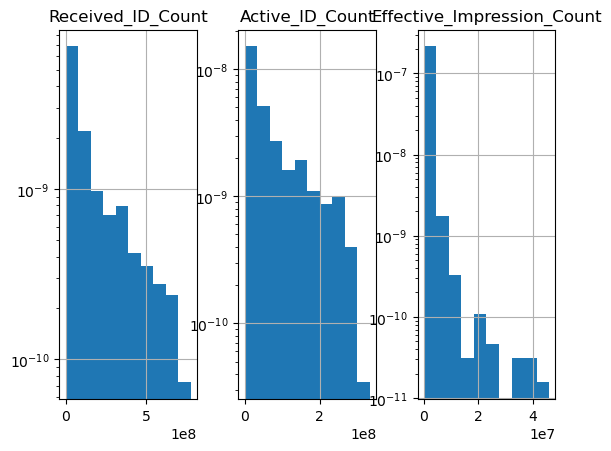

In [74]:
dat1[['Received_ID_Count', 'Active_ID_Count', 'Effective_Impression_Count']].astype(float).hist(density=True, layout=(1,3), log=True)

array([[<Axes: title={'center': 'Match_Pct'}>,
        <Axes: title={'center': 'Avg_Relevance'}>,
        <Axes: title={'center': 'Avg_Relevance_Percentile'}>]],
      dtype=object)

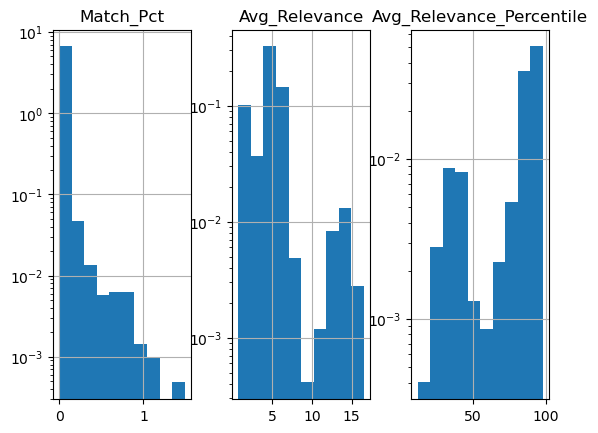

In [75]:
dat1[['Match_Pct', 'Avg_Relevance', 'Avg_Relevance_Percentile']].astype(float).hist(density=True, layout=(1,3), log=True)

## filter out bad rows

In [76]:
dat2 = dat1[dat1.Received_ID_Count > 0]

array([[<Axes: title={'center': 'Avg_Relevance'}>,
        <Axes: title={'center': 'Data_Cost'}>]], dtype=object)

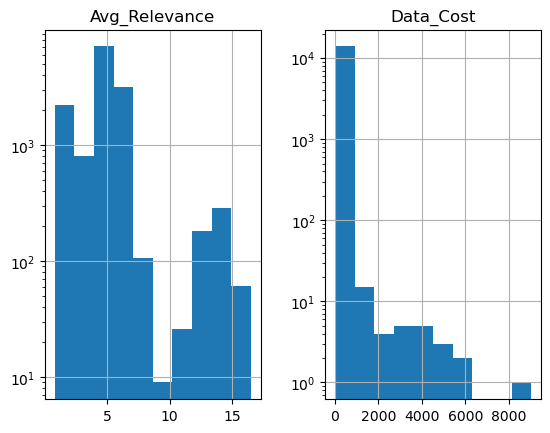

In [77]:
dat2[['Avg_Relevance', 'Data_Cost']].hist(log=True)

In [78]:
dat2[['Avg_Relevance', 'Data_Cost']].describe()

,Avg_Relevance,Data_Cost
count,13921.000000,13921.000000
mean,4.899698,15.005376
std,2.343923,175.976547
min,0.800000,0.000000
25%,4.200000,0.000000
50%,5.000000,0.020000
75%,5.600000,0.550000
max,16.500000,9027.490000


In [79]:
dat2[['Data_Cost']].describe(percentiles=[0.5, 0.7, 0.8, 0.9, 0.95, 0.99])

,Data_Cost
count,13921.000000
mean,15.005376
std,175.976547
min,0.000000
50%,0.020000
70%,0.270000
80%,1.180000
90%,7.720000
95%,32.390000
99%,245.488000


Text(0.5, 1.0, 'log2 (1 + data_cost)')

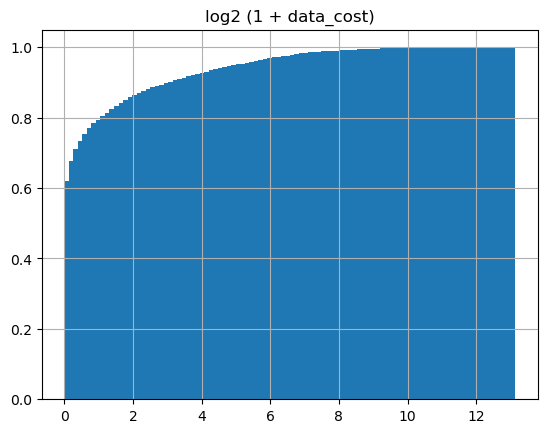

In [80]:
np.log2(dat2[['Data_Cost']] + 1).hist(bins=100, cumulative=True, density=True)
plt.title('log2 (1 + data_cost)')

# Model

In [81]:
yr = dat2['Avg_Relevance']
yd = dat2['Data_Cost'].astype(float) 

In [82]:
seg_col = 'segment_last'
#seg_col = 'segment_2'
#seg_col = 'Full_Path'

In [83]:
x_c_cols = [seg_col, 'week_start', 'Advertiser_Category', 'Third_Party_Data_Provider_Id', 'geo', 'segment_2']
x_n_cols = ['Received_ID_Count'] #[ 'Active_ID_Count_Percentile', 'Avg_Relevance_Percentile', 'Paid_Pct_Percentile']
# 'Avg_Value_Percentile' has NAs

In [84]:
Xn = pd.DataFrame(dat2[x_n_cols], dtype=float)
Xn['log_Received_ID_Count'] = Xn['Received_ID_Count'].apply(lambda x: np.log(x))

from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
Xn = pd.DataFrame(sc.fit_transform(Xn), columns=Xn.columns, index=Xn.index)

In [85]:
Xc = pd.get_dummies(dat2[x_c_cols])

In [86]:
dat2.head()

,Active_ID_Count,Active_ID_Count_Percentile,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,...,Third_Party_Data_Provider_Element_Id,Third_Party_Data_Provider_Id,Third_Party_Data_Sub_Provider_Id,Week_Start_Date,geo,Clean_Path,segment_last,segment_1,segment_2,week_start
99,18051800,96.9,Automotive,5.2,93.7,98.9,75.0,0.00,1,Data Alliance > Arts & Entertainment > Interes...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>arts&entertainment>interest>globa...,zoos&aquariums,dataalliance,arts&entertainment,2025-10-20
154,5075800,95.2,Automotive,4.4,87.6,98.2,69.0,0.01,176,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,f-type,dataalliance,automotive,2025-10-20
346,11493500,96.3,Automotive,5.3,94.1,98.9,75.0,0.00,13,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,cabriolet,dataalliance,automotive,2025-10-20
459,28809800,97.5,Automotive,5.4,94.4,99.0,76.0,28.06,1194128,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,4runner,dataalliance,automotive,2025-10-20
575,8348500,95.9,Automotive,5.2,93.5,98.9,75.0,0.00,2,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,i-pace,dataalliance,automotive,2025-10-20


In [87]:
#matches

In [88]:
Xc.head()

,segment_last_18+,segment_last_18-20,segment_last_18-44,segment_last_18-54,segment_last_18-64,segment_last_21-24,segment_last_25+,segment_last_25-29,segment_last_25-34,segment_last_25-44,...,segment_2_sports,segment_2_sportsenthusiasts,segment_2_style&fashion,segment_2_technology&computing,segment_2_thechangingconsumer,segment_2_travel,segment_2_travelers,segment_2_urlaudience,segment_2_us,segment_2_validateddemographic
99,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
154,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
346,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
459,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
575,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [89]:
Xn.head()

,Received_ID_Count,log_Received_ID_Count
99,-0.625948,-0.192218
154,-0.762721,-0.864363
346,-0.697304,-0.440389
459,-0.512074,0.054901
575,-0.730402,-0.613089


In [90]:
Xc.head()

,segment_last_18+,segment_last_18-20,segment_last_18-44,segment_last_18-54,segment_last_18-64,segment_last_21-24,segment_last_25+,segment_last_25-29,segment_last_25-34,segment_last_25-44,...,segment_2_sports,segment_2_sportsenthusiasts,segment_2_style&fashion,segment_2_technology&computing,segment_2_thechangingconsumer,segment_2_travel,segment_2_travelers,segment_2_urlaudience,segment_2_us,segment_2_validateddemographic
99,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
154,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
346,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
459,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
575,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [91]:
X = Xn.join(Xc)
X.head()

,Received_ID_Count,log_Received_ID_Count,segment_last_18+,segment_last_18-20,segment_last_18-44,segment_last_18-54,segment_last_18-64,segment_last_21-24,segment_last_25+,segment_last_25-29,...,segment_2_sports,segment_2_sportsenthusiasts,segment_2_style&fashion,segment_2_technology&computing,segment_2_thechangingconsumer,segment_2_travel,segment_2_travelers,segment_2_urlaudience,segment_2_us,segment_2_validateddemographic
99,-0.625948,-0.192218,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
154,-0.762721,-0.864363,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
346,-0.697304,-0.440389,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
459,-0.512074,0.054901,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
575,-0.730402,-0.613089,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [92]:
X.shape

(13921, 1150)

### Relevance

In [93]:
from sklearn.linear_model import Ridge

mod_r = Ridge(alpha=0.000001, fit_intercept=True)
mod_r.fit(X, yr)
mod_r.score(X, yr)

0.9337706713594505

In [94]:
coef_r = pd.DataFrame(mod_r.coef_, index=X.columns, columns=['beta'])
coef_r['abs_beta'] = coef_r['beta'].abs()
coef_r_sorted = coef_r.sort_values('abs_beta', ascending=False)

In [95]:
coef_r_sorted[coef_r_sorted.beta > 0].filter(regex=seg_col, axis='index').head(15)

,beta,abs_beta
segment_last_civilengineer,2.934340,2.934340
segment_last_graduation,2.890770,2.890770
segment_last_partyhosts,2.875770,2.875770
segment_last_warehousemanr,2.790830,2.790830
segment_last_outdoorentertainers,2.751136,2.751136
segment_last_legaleducation,2.739664,2.739664
segment_last_mechanicalengineer,2.492900,2.492900
segment_last_electronics,2.467466,2.467466
segment_last_furnishings,2.391081,2.391081
segment_last_cooks,2.312778,2.312778


In [96]:
coef_r_sorted[coef_r_sorted.beta < 0].filter(regex=seg_col, axis='index').head(15)

,beta,abs_beta
segment_last_cookingfats&oils,-6.644449,6.644449
segment_last_powersupplies,-6.323364,6.323364
segment_last_bookretailers,-5.337702,5.337702
segment_last_pc,-3.898118,3.898118
segment_last_consumerelectronics,-3.687920,3.687920
segment_last_used,-3.324644,3.324644
segment_last_fruitsnacks,-2.824236,2.824236
segment_last_rifter,-2.567222,2.567222
segment_last_hatchback,-2.540476,2.540476
segment_last_308sw,-2.464387,2.464387


<Axes: title={'center': 'seasonality of avg relevance'}, xlabel='week'>

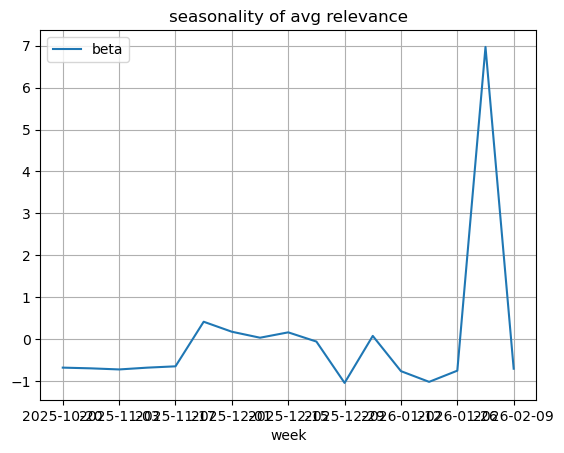

In [97]:
r_seas = coef_r.filter(regex='week_', axis='index')[['beta']].reset_index()
r_seas['week'] = r_seas['index'].apply(lambda x: x.split('_')[-1])
r_seas.plot(x='week', y='beta', grid=True, title='seasonality of avg relevance')

In [98]:
coef_r.filter(regex='Received', axis='index')

,beta,abs_beta
Received_ID_Count,-0.251933,0.251933
log_Received_ID_Count,0.204675,0.204675


In [99]:
coef_r.filter(regex='geo_', axis='index')

,beta,abs_beta
geo_APAC,-2.718168,2.718168
geo_Asia,-1.830375,1.830375
geo_Global,1.401210,1.401210
geo_US,1.912411,1.912411
geo_Unknown,1.234885,1.234885


In [100]:
coef_r.filter(regex='Third_Party_Data_Provider_Id', axis='index')

,beta,abs_beta
Third_Party_Data_Provider_Id_dav2shreths,-0.094247,0.094247
Third_Party_Data_Provider_Id_sharethis,0.094245,0.094245


### Revenue

In [101]:
from sklearn.linear_model import Ridge

mod_d_simple = Ridge(alpha=0.000001)
X2 = X[['Received_ID_Count']].join(yr)
mod_d_simple.fit(X2, yd)
mod_d_simple.score(X2, yd), mod_d_simple.coef_

(0.0056506632985759975, array([12.43674343,  1.44634142]))

In [102]:
X2.head()

,Received_ID_Count,Avg_Relevance
99,-0.625948,5.2
154,-0.762721,4.4
346,-0.697304,5.3
459,-0.512074,5.4
575,-0.730402,5.2


In [103]:
from sklearn.linear_model import Ridge

mod_d = Ridge(alpha=0.000001)
mod_d.fit(X, yd)
mod_d.score(X, yd)

0.37104991951579647

In [104]:
coef_d = pd.DataFrame(mod_d.coef_, index=X.columns, columns=['beta'])
coef_d['abs_beta'] = coef_d['beta'].abs()
coef_d_sorted = coef_d.sort_values('abs_beta', ascending=False)

In [105]:
coef_d_sorted[coef_d_sorted.beta > 0].filter(regex=seg_col, axis='index').head(15)

,beta,abs_beta
segment_last_adventuretravel,1374.424097,1374.424097
segment_last_greenliving&environmentalissues,1366.801034,1366.801034
segment_last_pickuptrucks&suvs,762.514535,762.514535
segment_last_females25-34,418.983584,418.983584
segment_last_spanish,283.637447,283.637447
segment_last_65-69,266.038387,266.038387
segment_last_25+,264.579635,264.579635
segment_last_males25-64,261.703736,261.703736
segment_last_25-64,260.593236,260.593236
segment_last_females65+,258.677743,258.677743


In [106]:
coef_d_sorted[coef_d_sorted.beta < 0].filter(regex=seg_col, axis='index').head(15)

,beta,abs_beta
segment_last_business&industrial,-190.828192,190.828192
segment_last_electricity,-177.979637,177.979637
segment_last_crops&seed,-172.925120,172.925120
segment_last_smallbusiness,-169.576633,169.576633
segment_last_renterinsurance,-167.923065,167.923065
segment_last_financialplanning&manment,-167.546640,167.546640
segment_last_civilengineering,-164.371075,164.371075
segment_last_agriculturalequipment,-162.607160,162.607160
segment_last_urban&regionalplanning,-161.191123,161.191123
segment_last_farms&ranches,-159.540884,159.540884


<Axes: title={'center': 'seasonality of revenue'}, xlabel='week'>

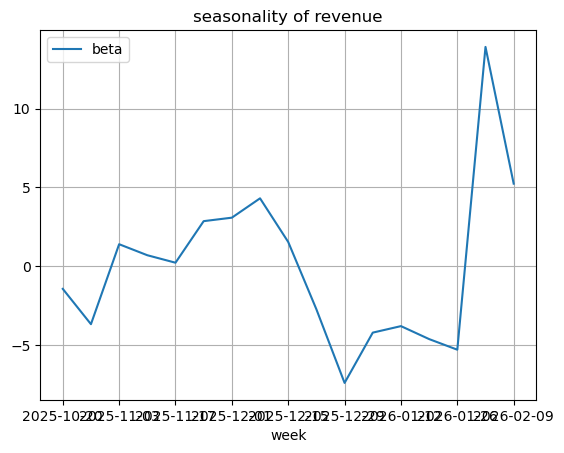

In [107]:
#coef_d.filter(regex='week', axis='index')

d_seas = coef_d.filter(regex='week_', axis='index')[['beta']].reset_index()
d_seas['week'] = d_seas['index'].apply(lambda x: x.split('_')[-1])
d_seas.plot(x='week', y='beta', grid=True, title='seasonality of revenue')

In [108]:
coef_d.filter(regex='Received', axis='index')

,beta,abs_beta
Received_ID_Count,13.051141,13.051141
log_Received_ID_Count,7.998994,7.998994


In [109]:
coef_d.filter(regex='geo_', axis='index')

,beta,abs_beta
geo_APAC,1.703988,1.703988
geo_Asia,1.636060,1.636060
geo_Global,14.193108,14.193108
geo_US,-26.603433,26.603433
geo_Unknown,9.070575,9.070575


In [110]:
coef_d.filter(regex='Third_Party_Data_Provider_Id', axis='index')

,beta,abs_beta
Third_Party_Data_Provider_Id_dav2shreths,-7.491632,7.491632
Third_Party_Data_Provider_Id_sharethis,7.491542,7.491542


In [111]:
segs_check = [x.replace(seg_col+'_', '') for x in coef_r_sorted.index[:1]]
dat2[dat2[seg_col].isin(segs_check)].head(5).T

""
Active_ID_Count
Active_ID_Count_Percentile
Advertiser_Category
Avg_Relevance
Avg_Relevance_Percentile
Avg_Value_Percentile
Avg_Value_Score
Data_Cost
Effective_Impression_Count
Full_Path


In [112]:
segs_d_check = [x.replace(seg_col+'_', '') for x in coef_d_sorted.index[:1]]
dat2[dat2[seg_col].isin(segs_d_check)].head(5).T

,14428,24124,49981,62660,75975
Active_ID_Count,76180500,911400,63634700,928200,884000
Active_ID_Count_Percentile,98.5,92.9,98.5,93.4,93.2
Advertiser_Category,Automotive,Automotive,Automotive,Automotive,Automotive
Avg_Relevance,4.8,1.3,5.1,1.3,1.3
Avg_Relevance_Percentile,91.3,34.2,93.1,34.6,34.8
Avg_Value_Percentile,98.5,90.1,98.5,90.4,90.1
Avg_Value_Score,71.0,28.0,64.0,26.0,25.0
Data_Cost,3730.49,0.01,318.49,0.01,0.01
Effective_Impression_Count,21896208,934,615221,1079,589
Full_Path,Global > travel > specialty travel > adventure...,Asia > Travel > Specialty Travel > Adventure T...,US > travel > specialty travel > adventure travel,Asia > Travel > Specialty Travel > Adventure T...,Asia > Travel > Specialty Travel > Adventure T...


In [113]:
coef_rd = coef_r.join(coef_d, lsuffix='_rel', rsuffix='_rev')

In [114]:
coef_seg = coef_rd.filter(regex=seg_col, axis='index')

In [115]:
coef_seg.head()

,beta_rel,abs_beta_rel,beta_rev,abs_beta_rev
segment_last_18+,0.410336,0.410336,244.011992,244.011992
segment_last_18-20,0.010380,0.010380,246.580601,246.580601
segment_last_18-44,0.275762,0.275762,236.040575,236.040575
segment_last_18-54,0.386393,0.386393,233.956373,233.956373
segment_last_18-64,0.428406,0.428406,230.902350,230.902350


In [116]:
coef_seg.corr()

,beta_rel,abs_beta_rel,beta_rev,abs_beta_rev
beta_rel,1.000000,-0.074156,0.184841,0.080726
abs_beta_rel,-0.074156,1.000000,0.065294,-0.020714
beta_rev,0.184841,0.065294,1.000000,0.725696
abs_beta_rev,0.080726,-0.020714,0.725696,1.000000


In [117]:
rel_rev_corr = round(coef_seg.corr().loc['beta_rel']['beta_rev'], 2)
rel_rev_corr

0.18

In [118]:
coef_seg.describe()

,beta_rel,abs_beta_rel,beta_rev,abs_beta_rev
count,1.060000e+03,1060.000000,1060.000000,1060.000000
mean,-6.167500e-09,0.468581,-0.000001,46.738162
std,7.330665e-01,0.563570,97.936049,86.052025
min,-6.644449e+00,0.000442,-190.828192,0.005431
25%,-3.676748e-01,0.172512,-27.497995,11.997508
50%,-5.281833e-02,0.356615,-15.777942,23.240392
75%,3.390809e-01,0.549876,7.559343,40.628268
max,2.934340e+00,6.644449,1374.424097,1374.424097


<Axes: title={'center': 'correlation between revenue and relevance'}, xlabel='beta_rel', ylabel='beta_rev'>

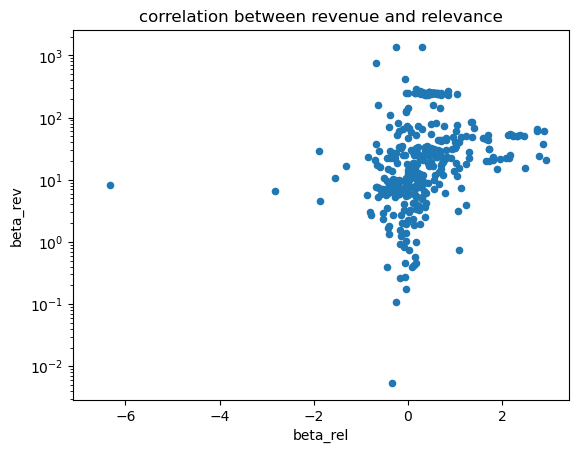

In [119]:
coef_seg.plot(kind='scatter', x='beta_rel', y='beta_rev', logy=True, title='correlation between revenue and relevance')

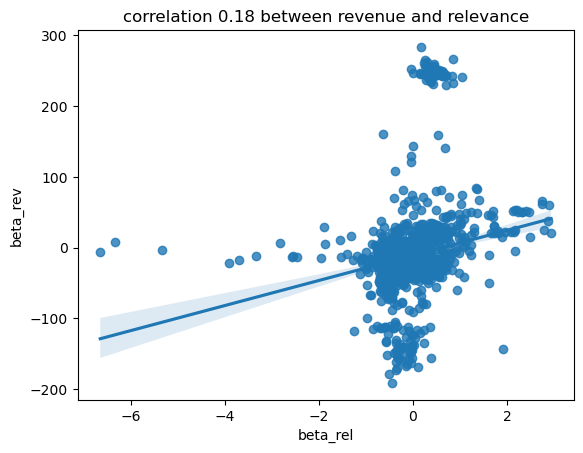

In [120]:
x = coef_seg[coef_seg.beta_rev < 300]['beta_rel'].values
y = coef_seg[coef_seg.beta_rev < 300]['beta_rev'].values

ax = sns.regplot(x=x, y=y,  robust=True)
ax.set(xlabel='beta_rel', ylabel='beta_rev')
# Optional: Add a title
ax.set_title(f'correlation {rel_rev_corr} between revenue and relevance')
plt.show()

array([[<Axes: title={'center': 'beta_rel'}>,
        <Axes: title={'center': 'beta_rev'}>]], dtype=object)

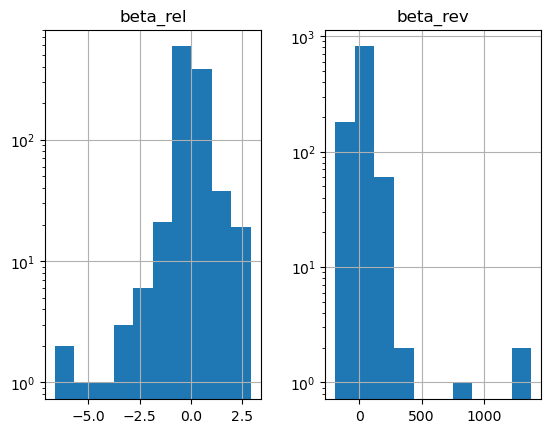

In [121]:
coef_seg[['beta_rel', 'beta_rev']].hist(log=True)

In [122]:
#coef_seg.plot(kind='scatter', x='beta_rel', y='beta_rev', logy=True, title='correlation between revenue and relevance')
#x = coef_seg['beta_rel'].values
#y = coef_seg['beta_rev'].values
#z = np.polyfit(x, y, deg=3)
#p = np.poly1d(z)
#line_y = p(x)
##line_y = slope * x + intercept
##plt.plot(x, line_y, color='red', linestyle='--', label='Trend Line')
#plt.scatter(x, line_y, color='red', label='Trend Line')

<Axes: xlabel='Avg_Relevance', ylabel='Data_Cost'>

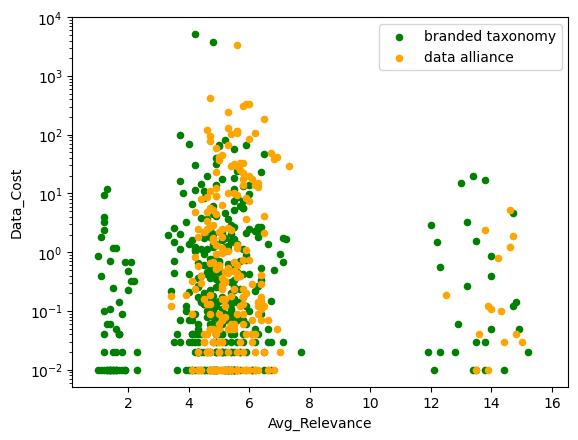

In [123]:
# for comparison
get_split_plots(dat1_sample, y='Data_Cost', x='Avg_Relevance', logy=True, logx=False)

In [124]:
import matplotlib.pyplot as plt

def dfScatter(df, xcol='beta', ycol='Received_ID_Count', catcol='criterion', logx=False, logy=False):
    #fig, ax = plt.subplots()
    categories = np.unique(df[catcol])
    colors = np.linspace(0, 1, len(categories))
    colordict = dict(zip(categories, colors))  

    colors = df[catcol].apply(lambda x: colordict[x])
    #x.scatter(df[xcol], df[ycol], c=colors, logx=logx, logy=logy)
    return df.plot(kind='scatter', x=xcol, y=ycol, logy=logy, logx=logx, c=colors)
    #return df.plot(kind='scatter', x='beta', y='Received_ID_Count', logy=logy, logx=logx, c=catcol, colormap='viridis')
    #return fig

# play around with sample size to make forecast

In [125]:
from sklearn.ensemble import RandomForestRegressor as RFR

In [126]:
X_rf = X[X.columns[X.columns != 'log_Received_ID_Count']]

In [127]:
X_rf[['Received_ID_Count']].head()

,Received_ID_Count
99,-0.625948
154,-0.762721
346,-0.697304
459,-0.512074
575,-0.730402


In [128]:
sc.inverse_transform(X[['Received_ID_Count',	'log_Received_ID_Count']].head())

array([[3.21545000e+07, 1.72860630e+01],
       [8.93680000e+06, 1.60056881e+01],
       [2.00416000e+07, 1.68133207e+01],
       [5.14851000e+07, 1.77568030e+01],
       [1.44231000e+07, 1.64843416e+01]])

In [129]:
sc.inverse_transform([[1, 1]])

array([[3.08165417e+08, 1.95571320e+01]])

In [130]:
mod_r_rf = RFR(max_depth=5)
mod_r_rf.fit(X_rf, yr)
mod_r_rf.score(X_rf, yr)

0.9199309551127939

In [131]:
coef_r_rf = pd.DataFrame(mod_r_rf.feature_importances_, index=X_rf.columns, columns=['feature_importance'])
coef_r_rf_sorted = coef_r_rf.sort_values('feature_importance', ascending=False)
coef_r_rf_sorted.head(20)

,feature_importance
week_start_2026-02-02,0.506812
geo_Asia,0.389173
geo_APAC,0.061529
Received_ID_Count,0.040016
week_start_2025-11-24,0.000785
week_start_2025-12-01,0.000240
segment_last_hatchback,0.000207
segment_last_used,0.000126
segment_last_vehiclemaintenance,0.000116
segment_last_agriculture,0.000111


In [132]:
mod_d_rf = RFR(max_depth=5)
mod_d_rf.fit(X_rf, yd)
mod_d_rf.score(X_rf, yd)

0.9173863723658326

In [133]:
coef_d_rf = pd.DataFrame(mod_d_rf.feature_importances_, index=X_rf.columns, columns=['feature_importance'])
coef_d_rf_sorted = coef_d_rf.sort_values('feature_importance', ascending=False)
coef_d_rf_sorted.head(20)

,feature_importance
geo_Global,0.333988
segment_last_adventuretravel,0.204234
segment_last_greenliving&environmentalissues,0.108665
week_start_2026-02-02,0.093797
Received_ID_Count,0.078391
segment_last_pickuptrucks&suvs,0.061279
week_start_2025-11-24,0.034924
week_start_2025-11-17,0.033874
week_start_2026-02-09,0.027347
week_start_2025-12-01,0.004135


In [134]:
samples = pd.DataFrame(np.arange(1, 1000, 10) * 1000000,  columns=['Received_ID_Count'])
samples['log_Received_ID_Count'] = samples['Received_ID_Count'].apply(lambda x: np.log(x))
samples_sc = pd.DataFrame(sc.transform(samples), columns=samples.columns, index=samples.index)

In [135]:
size_map = samples.join(samples_sc, rsuffix='_sc')

In [136]:
samples_sc2 = pd.DataFrame(samples_sc[['Received_ID_Count']], copy=True)
samples_sc2['fake_index'] = X_rf.index[0]

In [137]:
X_rf.head()

,Received_ID_Count,segment_last_18+,segment_last_18-20,segment_last_18-44,segment_last_18-54,segment_last_18-64,segment_last_21-24,segment_last_25+,segment_last_25-29,segment_last_25-34,...,segment_2_sports,segment_2_sportsenthusiasts,segment_2_style&fashion,segment_2_technology&computing,segment_2_thechangingconsumer,segment_2_travel,segment_2_travelers,segment_2_urlaudience,segment_2_us,segment_2_validateddemographic
99,-0.625948,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
154,-0.762721,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
346,-0.697304,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
459,-0.512074,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
575,-0.730402,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [138]:
X_rf['Received_ID_Count'].head()

99    -0.625948
154   -0.762721
346   -0.697304
459   -0.512074
575   -0.730402
Name: Received_ID_Count, dtype: float64

In [139]:
#samples.join(samples_sc, rsuffix='_sc').tail()

In [140]:
samples_sc2.set_index('fake_index')[['Received_ID_Count']]

,Received_ID_Count
fake_index,
99,-0.809476
99,-0.750567
99,-0.691658
99,-0.632749
99,-0.573840
...,...
99,4.786863
99,4.845772
99,4.904681


In [141]:
#t = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(X_rf2.head(1))
#t.shape

In [142]:
X_rf2 = X_rf[X_rf.columns[X_rf.columns != 'Received_ID_Count']]

X_rf_forecast_list = []
ss = 1000 # X_rf2.shape[0]
for idx in range(ss):
    samples_sc2 = pd.DataFrame(samples_sc[['Received_ID_Count']], copy=True)
    samples_sc2['fake_index'] = X_rf2.index[idx]
    temp = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(X_rf2)
    X_rf_forecast_list.append(temp)

X_rf_forecast_ss = pd.concat(X_rf_forecast_list)

In [143]:
yr_forecast = mod_r_rf.predict(X_rf_forecast_ss)
yd_forecast = mod_d_rf.predict(X_rf_forecast_ss)
X_rf_forecast_ss['relevance_forecast'] = yr_forecast
X_rf_forecast_ss['revenue_forecast'] = yd_forecast

In [144]:
def extract_geo(x, geos):
    for geo in geos:
        if x[geo]:
            return geo.split('_')[1]
    return "Unknown"

geos = ['geo_Asia', 'geo_US', 'geo_Global', 'geo_APAC']
X_rf_forecast_ss['geo'] = X_rf_forecast_ss[geos].apply(lambda x:  extract_geo(x, geos), axis=1)

In [145]:
X_rf_forecast = X_rf_forecast_ss.groupby(['geo', 'Received_ID_Count'])[['relevance_forecast', 'revenue_forecast']].mean().reset_index()

In [146]:
X_rf_forecast = X_rf_forecast.set_index('Received_ID_Count').join(
    size_map.set_index('Received_ID_Count_sc')[['Received_ID_Count']]
    )[['geo', 'Received_ID_Count', 'relevance_forecast', 'revenue_forecast']]
X_rf_forecast.head()

,geo,Received_ID_Count,relevance_forecast,revenue_forecast
Received_ID_Count,,,,
-0.809476,APAC,1000000,1.183804,5.771376
-0.750567,APAC,11000000,1.183804,5.771376
-0.691658,APAC,21000000,1.270731,5.771376
-0.632749,APAC,31000000,1.270731,5.771376
-0.573840,APAC,41000000,1.270731,5.771376


/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='relevance_forecast'>

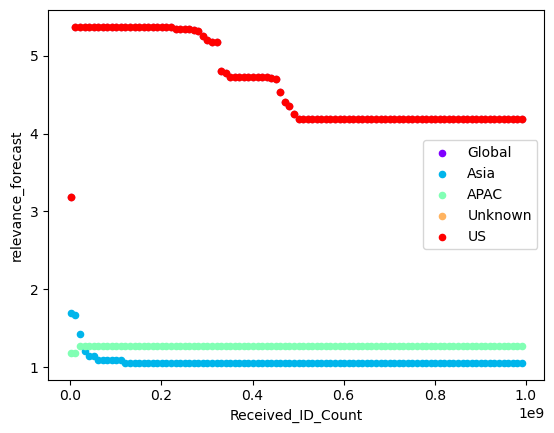

In [147]:
get_split_plots2(X_rf_forecast, y='relevance_forecast', x='Received_ID_Count', by='geo', logy=False, logx=False)

/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  scatter = ax.scatter(
/opt/anaconda3/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1345: UserWarning: *c* argument looks li

<Axes: xlabel='Received_ID_Count', ylabel='revenue_forecast'>

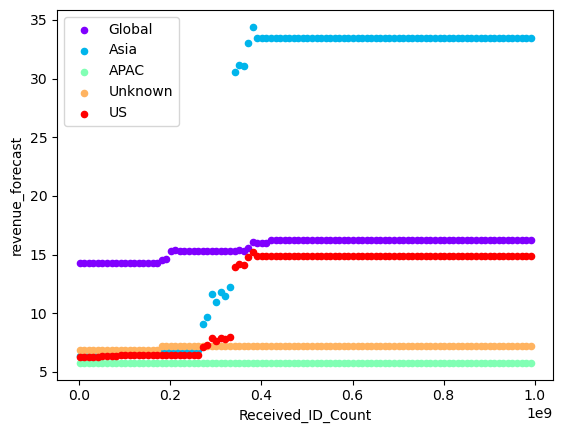

In [148]:
get_split_plots2(X_rf_forecast, y='revenue_forecast', x='Received_ID_Count', by='geo', logy=False, logx=False)

<Axes: xlabel='Received_ID_Count_unscaled', ylabel='Revenue'>

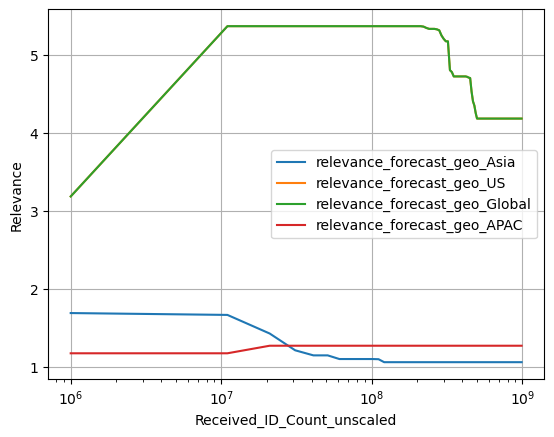

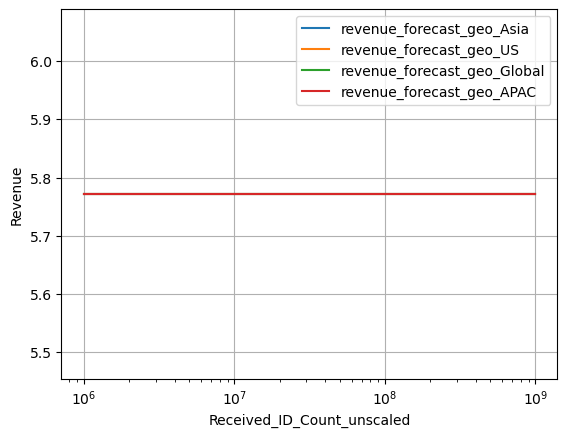

In [149]:
X_rf2 = X_rf[X_rf.columns[X_rf.columns != 'Received_ID_Count']]
samples_sc2 = pd.DataFrame(samples_sc[['Received_ID_Count']], copy=True)
samples_sc2['fake_index'] = X_rf2.index[0]

X_rf_forecast = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(X_rf2.head(1))

geos = ['geo_Asia', 'geo_US', 'geo_Global', 'geo_APAC']

yr_forecast = {}
yd_forecast = {}

for geo in geos:
    X_rf_forecast[geos] = False
    X_rf_forecast[geo] = True
    yr_forecast[geo] = mod_r_rf.predict(X_rf_forecast)
    yd_forecast[geo] = mod_d_rf.predict(X_rf_forecast)

for geo in geos:
    X_rf_forecast['relevance_forecast_' + geo] = yr_forecast[geo]
    X_rf_forecast['revenue_forecast_' + geo] = yd_forecast[geo]
    
X_rf_forecast['Received_ID_Count_unscaled'] = samples['Received_ID_Count'].values

rel_cols = ['relevance_forecast_' + geo for geo in geos]
rev_cols = ['revenue_forecast_' + geo for geo in geos]

X_rf_forecast.plot(x='Received_ID_Count_unscaled', y=rel_cols, grid=True, logx=True, ylabel='Relevance')
X_rf_forecast.plot(x='Received_ID_Count_unscaled', y=rev_cols, grid=True, logx=True, ylabel='Revenue')

In [150]:
def plot_seg_forecasts(fc,
        x = 'Received_ID_Count_unscaled',
        y1 = 'relevance_forecast',
        y2 = 'revenue_forecast',
        x11 = None, #'Received_ID_Count_orig',
        y11 = None, #'current_size',
        title = '',
        legend_loc = None
    ):
    # 1. Get the current axes and create the second axes object
    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx() # Instantiate a second axis that shares the same x-axis
    
    # 2. Plot the data on each axes object
    #y1 = y[0] if isinstance(y, list) else y
    ax1.plot(fc[x], fc[y1], color='blue', marker='.', label=y1, alpha=0.5)
    if x11 is not None and y11 is not None:
        ax1.plot(fc[x11], fc[y11], color='red', label=y11, alpha=0.7)
    ax2.plot(fc[x], fc[y2], color='green', marker='.', label=y2 + ' (right)')
    
    # 3. Set the labels
    ax1.set_xlabel(x)
    ax1.set_ylabel(y1, color='blue')
    ax2.set_ylabel(y2, color='green')
    
    # Optional: Improve layout and display legend
    if legend_loc:
        fig.tight_layout() # Ensures labels don't get clipped
        #ax1.legend(loc='lower left')
        #ax2.legend(loc='lower right')
        ax1.legend(loc=legend_loc)
        ax2.legend(loc=legend_loc)

    ax1.set_title(title)
    plt.show()


def get_seg_forecasts(X_rf, samples_sc, samples, seg_name, get_current_size=False, sc=None):
    idx=0
    X_rf = X_rf[X_rf[seg_name] == 1]#.tail(1)
    samples_sc2 = pd.DataFrame(samples_sc[['Received_ID_Count']], copy=True)
    samples_sc2['fake_index'] = X_rf.index[idx]
    X_rf2 = X_rf[X_rf.columns[X_rf.columns != 'Received_ID_Count']]
    X_rf_forecast = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(
        X_rf2.head(idx + 1).tail(1)
    )
    yr_forecast = mod_r_rf.predict(X_rf_forecast)
    yd_forecast = mod_d_rf.predict(X_rf_forecast)
    X_rf_forecast['relevance_forecast'] = yr_forecast
    X_rf_forecast['revenue_forecast'] = yd_forecast
        
    X_rf_forecast['Received_ID_Count_unscaled'] = samples['Received_ID_Count'].values
    
    if get_current_size:
        X_rf_forecast['Received_ID_Count_orig'] = sc.inverse_transform(
            [[X_rf['Received_ID_Count'].values[idx], 1]]
        )[0][0]
        mx_rel = X_rf_forecast['relevance_forecast'].max()
        mn_rel = X_rf_forecast['relevance_forecast'].min()
        mx_sz = X_rf_forecast['Received_ID_Count'].max()
        mn_sz = X_rf_forecast['Received_ID_Count'].min()
        X_rf_forecast['current_size'] = mn_rel + (X_rf_forecast['Received_ID_Count'] - mn_sz) * (mx_rel - mn_rel) / (mx_sz - mn_sz)
    
    #temp2 = pd.DataFrame(X_rf_forecast[X_rf_forecast.columns[["geo" in c for c in X_rf_forecast.columns]]].sum())
    #temp2.columns = ['sum']
    #print(temp2[temp2["sum"] > 0].index)

    return X_rf_forecast
    

def get_forecasts(X_rf, samples_sc, samples, idx=0, seg_col='segment_last', seg_name=None):
    samples_sc2 = pd.DataFrame(samples_sc[['Received_ID_Count']], copy=True)
    samples_sc2['fake_index'] = X_rf.index[idx]
    
    X_rf2 = X_rf[X_rf.columns[X_rf.columns != 'Received_ID_Count']]
    X_rf_forecast = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(
        X_rf2.head(idx + 1).tail(1)
    )
    
    geos = ['geo_Asia', 'geo_US', 'geo_Global', 'geo_APAC']
    
    yr_forecast = {}
    yd_forecast = {}
    
    for geo in geos:
        X_rf_forecast[geos] = False
        X_rf_forecast[geo] = True
        yr_forecast[geo] = mod_r_rf.predict(X_rf_forecast)
        yd_forecast[geo] = mod_d_rf.predict(X_rf_forecast)
    
    for geo in geos:
        g = geo.split('_')[1]
        X_rf_forecast['relevance_' + g] = yr_forecast[geo]
        X_rf_forecast['revenue_' + g] = yd_forecast[geo]
        
    X_rf_forecast['Received_ID_Count_unscaled'] = samples['Received_ID_Count'].values

    print (idx)
    temp = pd.DataFrame(X_rf_forecast[X_rf_forecast.columns[[seg_col in c for c in X_rf_forecast.columns]]].sum())
    temp.columns = ['sum']
    print(temp[temp["sum"] > 0].index)
    #temp2 = pd.DataFrame(X_rf_forecast[X_rf_forecast.columns[["geo" in c for c in X_rf_forecast.columns]]].sum())
    #temp2.columns = ['sum']
    #print(temp2[temp2["sum"] > 0].index)
    print(X_rf_forecast.shape)

    return X_rf_forecast

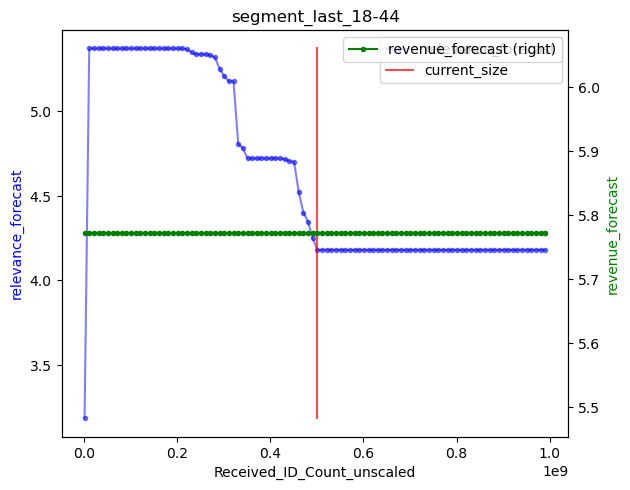

In [151]:
fc_seg = get_seg_forecasts(X_rf, samples_sc, samples, seg_name='segment_last_18-44', get_current_size=True, sc=sc)
plot_seg_forecasts(fc_seg, y1='relevance_forecast', y2='revenue_forecast',
                   y11 = 'current_size', x11='Received_ID_Count_orig',
                   title='segment_last_18-44', legend_loc='best')

In [152]:
X_rf2.shape

(13921, 1148)

In [153]:
X_rf2 = X_rf[X_rf.columns[X_rf.columns != 'Received_ID_Count']]
X_rf_forecast = samples_sc2.set_index('fake_index')[['Received_ID_Count']].join(X_rf2.head(1))
X_rf_forecast.shape

(100, 1149)

In [154]:
yr_forecast = mod_r_rf.predict(X_rf_forecast)
yd_forecast = mod_d_rf.predict(X_rf_forecast)
X_rf_forecast['relevance_forecast'] = yr_forecast
X_rf_forecast['revenue_forecast'] = yd_forecast
X_rf_forecast['Received_ID_Count_unscaled'] = samples['Received_ID_Count'].values

<Axes: xlabel='Received_ID_Count_unscaled'>

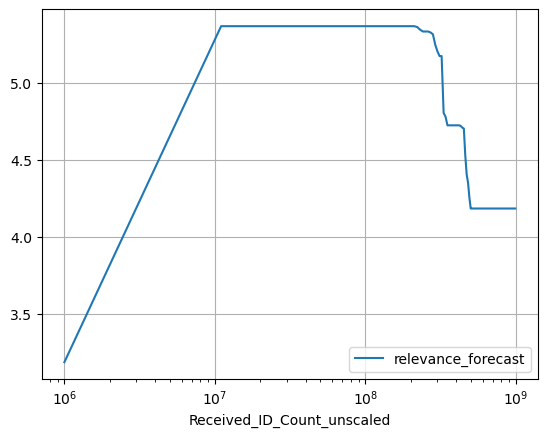

In [155]:
X_rf_forecast.plot(x='Received_ID_Count_unscaled', y='relevance_forecast', grid=True, logx=True)

<Axes: xlabel='Received_ID_Count_unscaled'>

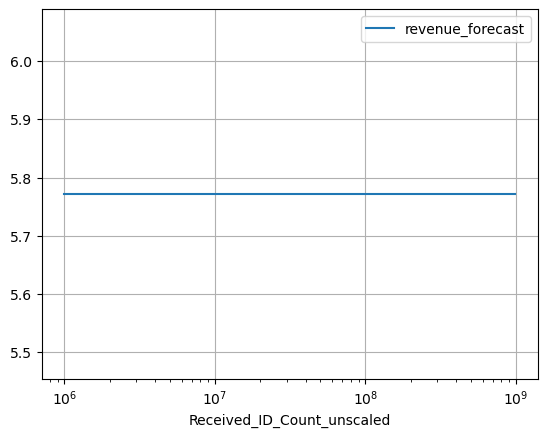

In [156]:
X_rf_forecast.plot(x='Received_ID_Count_unscaled', y='revenue_forecast', grid=True, logx=True)

## check current allocation

In [157]:
seg_size = dat1.pivot_table(index='Full_Path', columns='week_start', values='Received_ID_Count')

In [158]:
seg_size['Full_Path'] = 'Full_Path_' + seg_size.index

In [159]:
seg_size_beta = seg_size.set_index('Full_Path').join(coef_r).join(coef_d, rsuffix='_rev', lsuffix='_rel')

In [160]:
seg_size_beta

,2025-10-20,2025-10-27,2025-11-03,2025-11-10,2025-11-17,2025-11-24,2025-12-01,2025-12-08,2025-12-15,2025-12-22,...,2026-01-05,2026-01-12,2026-01-19,2026-01-26,2026-02-02,2026-02-09,beta_rel,abs_beta_rel,beta_rev,abs_beta_rev
Full_Path,,,,,,,,,,,,,,,,,,,,,
Full_Path_Asia > Arts & Entertainment > Entertainment Industry > Film & TV Industry,NaN,NaN,NaN,NaN,283700.0,342500.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Full_Path_Asia > Arts & Entertainment > Events & Listings > Concerts & Music Festivals,NaN,NaN,NaN,1525700.0,1481100.0,1319500.0,1251600.0,1215600.0,1434500.0,1687400.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Full_Path_Asia > Arts & Entertainment > Events & Listings > Film Festivals,NaN,NaN,NaN,NaN,NaN,338400.0,318900.0,283300.0,317700.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Full_Path_Asia > Arts & Entertainment > Events & Listings > Live Sporting Events,NaN,NaN,674300.0,720800.0,725800.0,696300.0,609400.0,527200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Full_Path_Asia > Arts & Entertainment > Humor > Spoofs & Satire,NaN,NaN,NaN,133500.0,NaN,115600.0,107200.0,NaN,128400.0,NaN,...,174500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Full_Path_US > sports > winter sports > skiing & snowboarding,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,244521500.0,NaN,NaN,NaN,NaN,NaN
Full_Path_US > travel > specialty travel > adventure travel,91591200.0,91591200.0,129702000.0,175996700.0,216205600.0,266423900.0,269109400.0,278273600.0,298262500.0,327710400.0,...,317197300.0,305075400.0,269865600.0,276892200.0,296650000.0,342232000.0,NaN,NaN,NaN,NaN
Full_Path_Unavailable,NaN,NaN,48343000.0,38445100.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [161]:
seg_size_beta.corr()

,2025-10-20,2025-10-27,2025-11-03,2025-11-10,2025-11-17,2025-11-24,2025-12-01,2025-12-08,2025-12-15,2025-12-22,...,2026-01-05,2026-01-12,2026-01-19,2026-01-26,2026-02-02,2026-02-09,beta_rel,abs_beta_rel,beta_rev,abs_beta_rev
2025-10-20,1.000000,0.998581,0.984004,0.971157,0.947697,0.918931,0.921712,0.919976,0.917896,0.912050,...,0.902338,0.901477,0.904148,0.903852,0.900963,0.895842,NaN,NaN,NaN,NaN
2025-10-27,0.998581,1.000000,0.986210,0.971000,0.949428,0.919694,0.922383,0.921498,0.919967,0.914644,...,0.902947,0.901919,0.905306,0.904584,0.902457,0.896437,NaN,NaN,NaN,NaN
2025-11-03,0.984004,0.986210,1.000000,0.993856,0.981578,0.963391,0.958702,0.954368,0.952551,0.947688,...,0.943559,0.943600,0.943756,0.955693,0.954717,0.952423,NaN,NaN,NaN,NaN
2025-11-10,0.971157,0.971000,0.993856,1.000000,0.993134,0.978604,0.972741,0.966061,0.964090,0.958398,...,0.959645,0.960328,0.961570,0.961896,0.956156,0.957667,NaN,NaN,NaN,NaN
2025-11-17,0.947697,0.949428,0.981578,0.993134,1.000000,0.993387,0.990358,0.986473,0.984851,0.981382,...,0.981890,0.981590,0.982071,0.981293,0.976509,0.977865,NaN,NaN,NaN,NaN
2025-11-24,0.918931,0.919694,0.963391,0.978604,0.993387,1.000000,0.997237,0.994228,0.993299,0.991382,...,0.990566,0.990836,0.990639,0.989375,0.985219,0.985615,NaN,NaN,NaN,NaN
2025-12-01,0.921712,0.922383,0.958702,0.972741,0.990358,0.997237,1.000000,0.996074,0.995483,0.994656,...,0.993556,0.994423,0.993902,0.992163,0.989033,0.989157,NaN,NaN,NaN,NaN
2025-12-08,0.919976,0.921498,0.954368,0.966061,0.986473,0.994228,0.996074,1.000000,0.999633,0.998827,...,0.998076,0.997342,0.996315,0.994342,0.992328,0.991417,NaN,NaN,NaN,NaN
2025-12-15,0.917896,0.919967,0.952551,0.964090,0.984851,0.993299,0.995483,0.999633,1.000000,0.999719,...,0.998974,0.998356,0.997381,0.995557,0.993717,0.993231,NaN,NaN,NaN,NaN
2025-12-22,0.912050,0.914644,0.947688,0.958398,0.981382,0.991382,0.994656,0.998827,0.999719,1.000000,...,0.999292,0.998722,0.997632,0.995751,0.993987,0.993476,NaN,NaN,NaN,NaN
